End-to-End ETL and Data Analysis Pipeline

## Project Overview

This project focuses on analyzing the Sample Superstore dataset using Python and Pandas. The dataset contains information about orders, customers, products, sales, discounts, shipping, and profits.

The main goal is to extract, explore, clean, and transform the data, answer meaningful business questions, and identify useful insights. The project will also include designing a relational database, loading data into the database, and creating SQL reports.

## Project Objectives

- Explore the dataset and understand its structure.
- Identify and address data quality issues.
- Clean and transform the data for analysis.
- Answer business questions and identify data-driven insights.
- Design a relational database and load the transformed data.
- Create SQL queries to generate meaningful reports.

## Dataset Information

**Dataset name:** Sample - Superstore.csv

**Tools used:** Python, Pandas, Matplotlib, and SQL.

**Dataset contents:** Orders, customers, products, shipping information, sales, discounts, and profits.

## Project Phases

1. Data Acquisition and Extraction
2. Exploratory Data Analysis (EDA)
3. Data Cleaning and Transformation
4. Analytical Questions and Insights
5. Relational Database Design
6. Python-to-Database ETL
7. SQL Reporting and Analysis

## Phase 1: Data Acquisition and Extraction

In this phase, the Superstore dataset is loaded into Python using Pandas. The original CSV file is preserved in the raw data folder so that the source data remains unchanged. The dataset is then checked to understand its size and structure before further analysis.

### Data Source and Extraction

The dataset used in this project is `Sample - Superstore.csv`, stored in the project's `data/raw/` folder. It contains 9,994 records and 21 original columns describing orders, customers, products, shipping, sales, discounts, and profits. The dataset was loaded into Python using Pandas for further exploration and processing. The original CSV file is preserved separately from the transformed data.

**Extraction result:** 9,994 rows and 21 original columns were loaded successfully.


In [67]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/Sample - Superstore.csv")
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
df.head()


Dataset loaded successfully!
Dataset shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164





# 1. Number of rows and columns
print("Dataset Shape:", df.shape)

# 2. Column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Data types
print("\nData Types:")
print(df.dtypes)

# 4. First five records
print("\nFirst Five Records:")
display(df.head())

# 5. Summary statistics
print("\nSummary Statistics:")
display(df.describe(include="all").T)

# 6. Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 7. Duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# 8. Unique values in important columns
for col in ["Category", "Region", "Segment", "Ship Mode"]:
    print(f"\nUnique values in {col}:")
    print(df[col].unique())
    print("Number of unique values:", df[col].nunique())


In [68]:

# 1. Total sales and profit
print("Total Sales:", round(df["Sales"].sum(), 2))
print("Total Profit:", round(df["Profit"].sum(), 2))

# 2. Sales by category
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
print("\nSales by Category:")
display(category_sales)

# 3. Profit by region
region_profit = df.groupby("Region")["Profit"].sum().sort_values(ascending=False)
print("\nProfit by Region:")
display(region_profit)

# 4. Top 10 products by sales
product_sales = df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False)
print("\nTop 10 Products by Sales:")
display(product_sales.head(10))

# 5. Monthly sales
df["Order Date"] = pd.to_datetime(df["Order Date"])
monthly_sales = df.groupby(df["Order Date"].dt.to_period("M"))["Sales"].sum()
print("\nMonthly Sales:")
display(monthly_sales.head(12))


Total Sales: 2297200.86
Total Profit: 286397.02

Sales by Category:


Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64


Profit by Region:


Region
West       108418.4489
East        91522.7800
South       46749.4303
Central     39706.3625
Name: Profit, dtype: float64


Top 10 Products by Sales:


Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


Monthly Sales:


Order Date
2014-01    14236.8950
2014-02     4519.8920
2014-03    55691.0090
2014-04    28295.3450
2014-05    23648.2870
2014-06    34595.1276
2014-07    33946.3930
2014-08    27909.4685
2014-09    81777.3508
2014-10    31453.3930
2014-11    78628.7167
2014-12    69545.6205
Freq: M, Name: Sales, dtype: float64

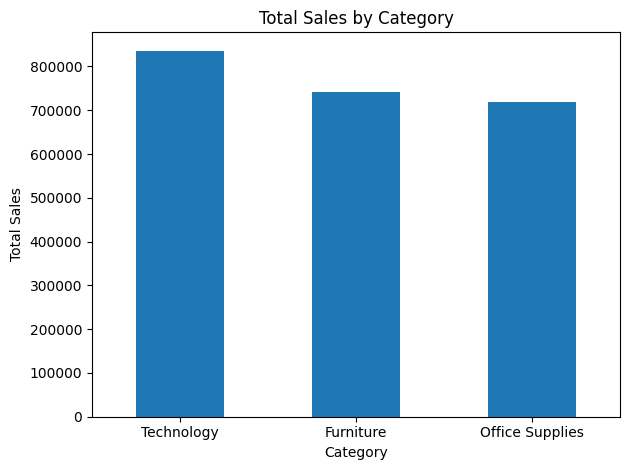

In [69]:

category_sales.plot(kind="bar", title="Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


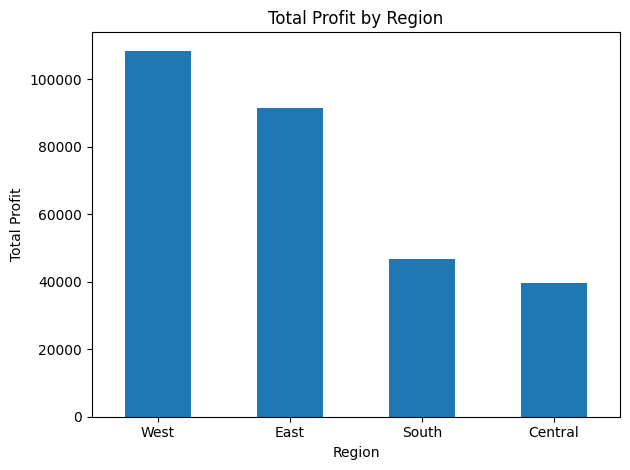

In [70]:
region_profit.plot(kind="bar", title="Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

KeyboardInterrupt: 

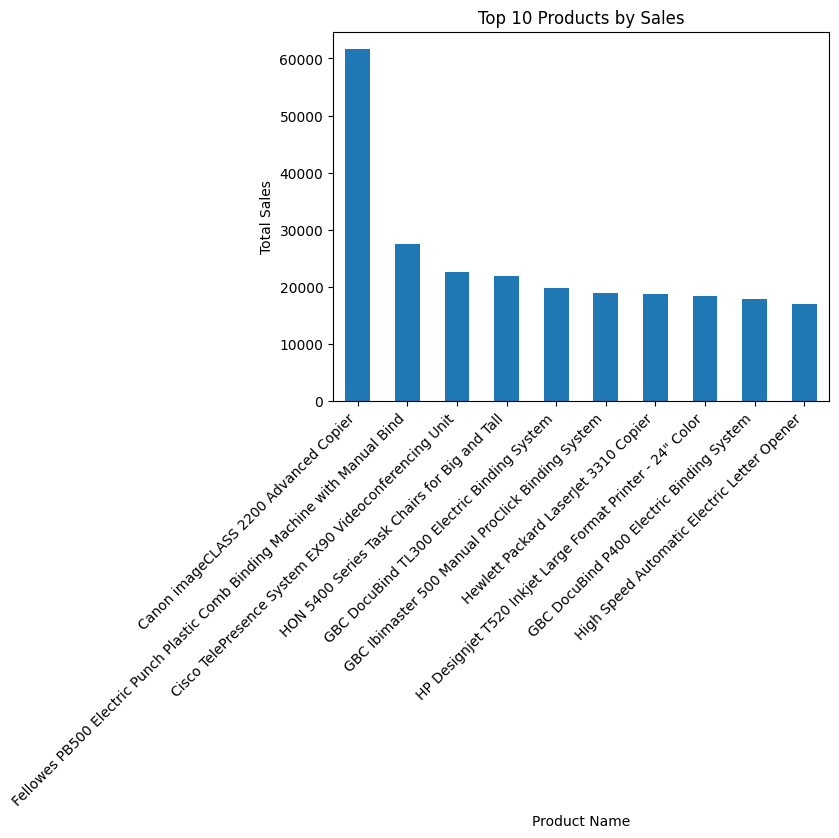

In [71]:
top_products = product_sales.sort_values(ascending=False).head(10)

top_products.plot(kind="bar", title="Top 10 Products by Sales")
plt.xlabel("Product Name")
plt.ylabel("Total Sales")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

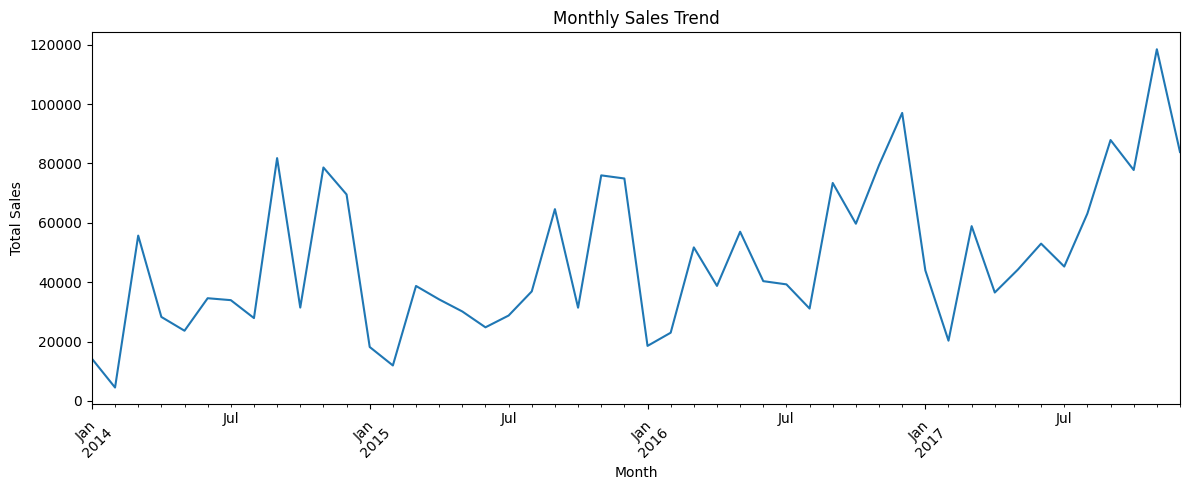

In [ ]:
monthly_sales.plot(kind="line", title="Monthly Sales Trend", figsize=(12, 5))
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Profit by Category:


Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728
Name: Profit, dtype: float64

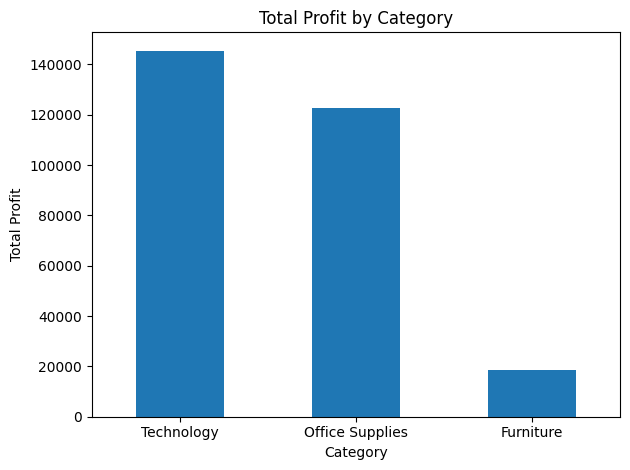

In [ ]:
category_profit = df.groupby("Category")["Profit"].sum().sort_values(ascending=False)

print("Profit by Category:")
display(category_profit)

category_profit.plot(kind="bar", title="Total Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

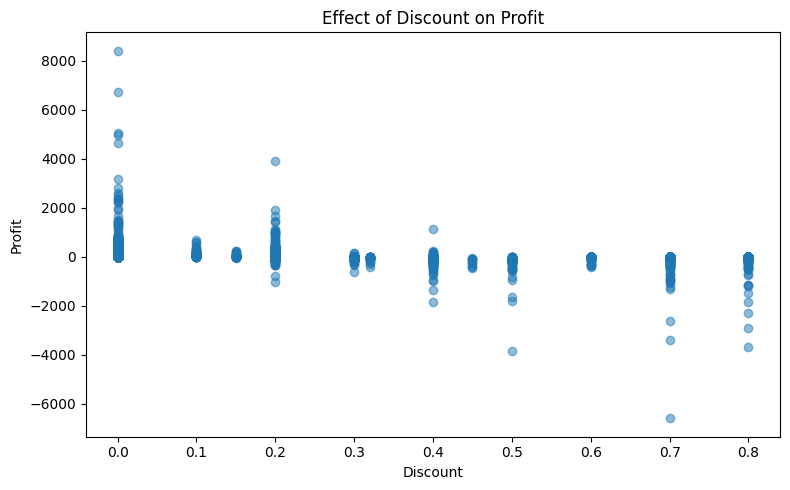

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Discount"], df["Profit"], alpha=0.5)
plt.title("Effect of Discount on Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()

Profit by Sub-Category:


Sub-Category
Copiers        55617.8249
Phones         44515.7306
Accessories    41936.6357
Paper          34053.5693
Binders        30221.7633
Chairs         26590.1663
Storage        21278.8264
Appliances     18138.0054
Furnishings    13059.1436
Envelopes       6964.1767
Art             6527.7870
Labels          5546.2540
Machines        3384.7569
Fasteners        949.5182
Supplies       -1189.0995
Bookcases      -3472.5560
Tables        -17725.4811
Name: Profit, dtype: float64

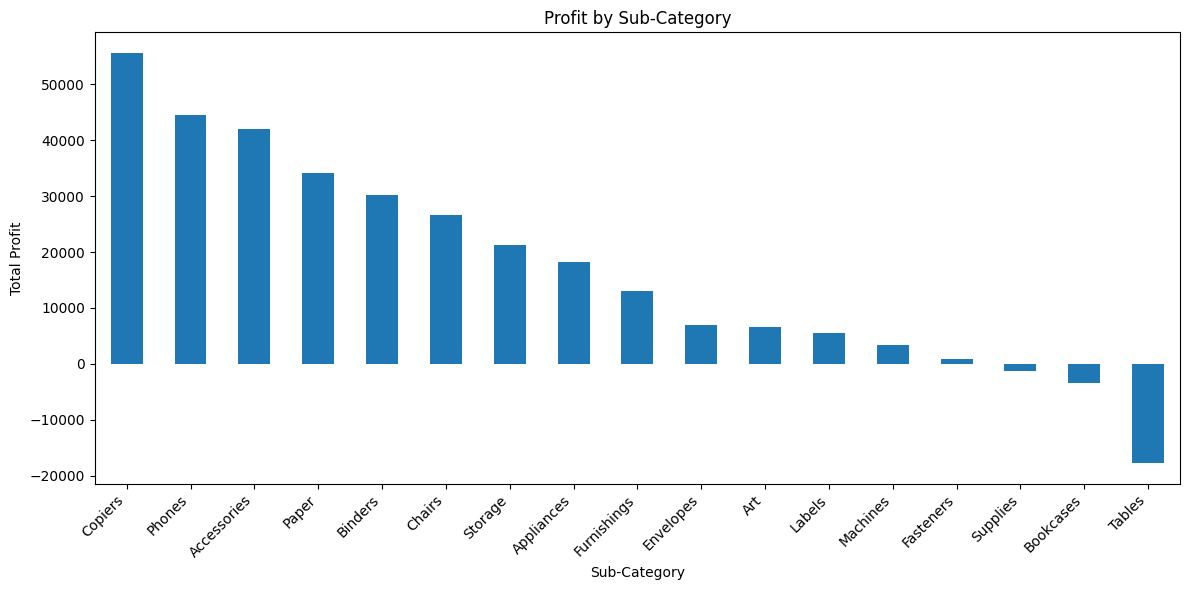

In [ ]:
subcategory_profit = df.groupby("Sub-Category")["Profit"].sum().sort_values(ascending=False)

print("Profit by Sub-Category:")
display(subcategory_profit)

subcategory_profit.plot(kind="bar", title="Profit by Sub-Category", figsize=(12, 6))
plt.xlabel("Sub-Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Sales and Profit by Region:


,Sales,Profit
Region,,
Central,501239.8908,39706.3625
East,678781.2400,91522.7800
South,391721.9050,46749.4303
West,725457.8245,108418.4489


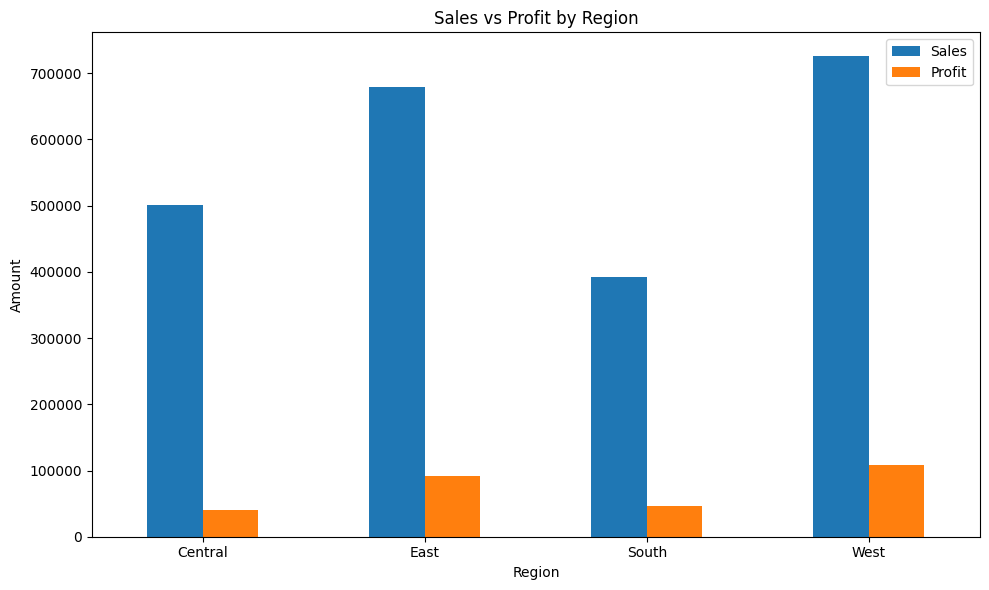

In [ ]:
region_analysis = df.groupby("Region")[["Sales", "Profit"]].sum()

print("Sales and Profit by Region:")
display(region_analysis)

region_analysis.plot(kind="bar", figsize=(10, 6), title="Sales vs Profit by Region")
plt.xlabel("Region")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
print("===== TOTAL SALES AND PROFIT =====")
print("Total Sales:", round(df["Sales"].sum(), 2))
print("Total Profit:", round(df["Profit"].sum(), 2))

print("\n===== SALES BY CATEGORY =====")
print(category_sales)

print("\n===== PROFIT BY REGION =====")
print(region_profit)

print("\n===== TOP 10 PRODUCTS BY SALES =====")
print(product_sales.head(10))

print("\n===== PROFIT BY SUB-CATEGORY =====")
print(category_profit if False else subcategory_profit)

print("\n===== SALES AND PROFIT BY REGION =====")
print(region_analysis)

===== TOTAL SALES AND PROFIT =====
Total Sales: 2297200.86
Total Profit: 286397.02

===== SALES BY CATEGORY =====
Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64

===== PROFIT BY REGION =====
Region
West       108418.4489
East        91522.7800
South       46749.4303
Central     39706.3625
Name: Profit, dtype: float64

===== TOP 10 PRODUCTS BY SALES =====
Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packa

Sales and Profit by Customer Segment:


,Sales,Profit
Segment,,
Consumer,1.161401e+06,134119.2092
Corporate,7.061464e+05,91979.1340
Home Office,4.296531e+05,60298.6785


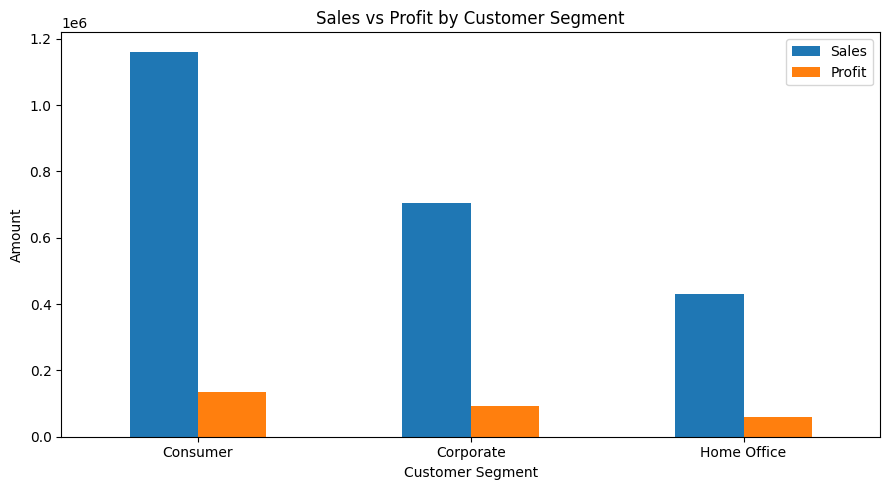

In [ ]:
segment_analysis = df.groupby("Segment")[["Sales", "Profit"]].sum()

print("Sales and Profit by Customer Segment:")
display(segment_analysis)

segment_analysis.plot(
    kind="bar",
    figsize=(9, 5),
    title="Sales vs Profit by Customer Segment"
)
plt.xlabel("Customer Segment")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Sales and Profit by Ship Mode:


,Sales,Profit
Ship Mode,,
Standard Class,1.358216e+06,164088.7875
Second Class,4.591936e+05,57446.6354
First Class,3.514284e+05,48969.8399
Same Day,1.283631e+05,15891.7589


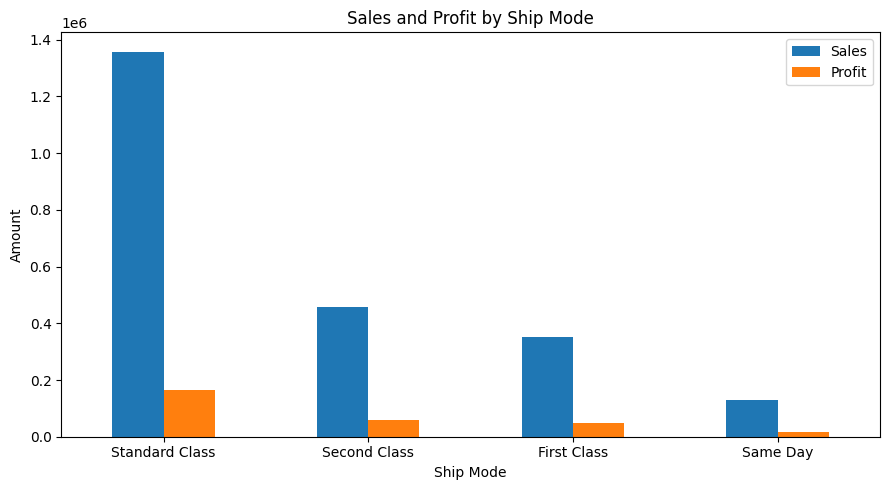

In [ ]:
ship_analysis = df.groupby("Ship Mode")[["Sales", "Profit"]].sum().sort_values(
    by="Sales", ascending=False
)

print("Sales and Profit by Ship Mode:")
display(ship_analysis)

ship_analysis.plot(
    kind="bar",
    figsize=(9, 5),
    title="Sales and Profit by Ship Mode"
)
plt.xlabel("Ship Mode")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

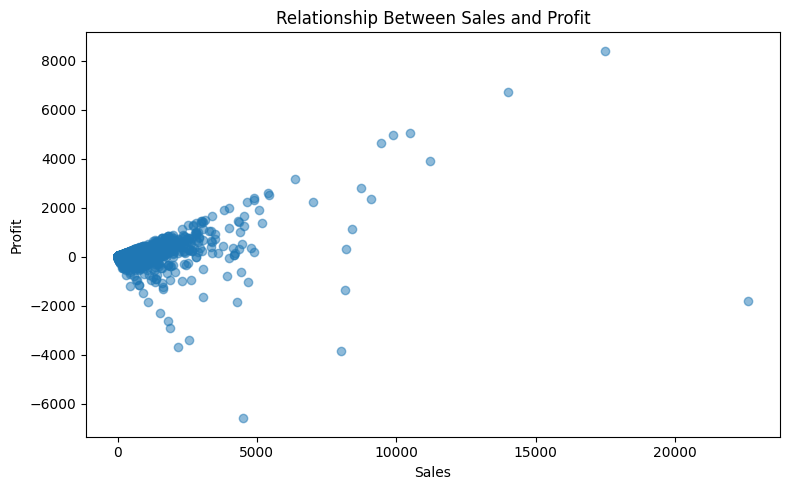

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Sales"], df["Profit"], alpha=0.5)
plt.title("Relationship Between Sales and Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()

## Phase 2: Exploratory Data Analysis (EDA)

In this phase, the dataset is explored to understand its structure, data types, numerical summaries, and data quality. Missing values, duplicate rows, and data types are checked to identify potential issues before cleaning and transformation. Sales and profit patterns are also examined using summary statistics and visualizations.

In [ ]:

# Check for missing values in each column
print("===== MISSING VALUES =====")
print(df.isnull().sum())

# Check for duplicate rows
print("\n===== DUPLICATE ROWS =====")
print("Number of duplicate rows:", df.duplicated().sum())

# Check column data types
print("\n===== DATA TYPES =====")
print(df.dtypes)


===== MISSING VALUES =====
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

===== DUPLICATE ROWS =====
Number of duplicate rows: 0

===== DATA TYPES =====
Row ID                    int64
Order ID                 object
Order Date       datetime64[ns]
Ship Date                object
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code               int64
Region                   object
Product ID               object
Category                 object
S

In [ ]:
print("Dataset shape:", df.shape)
print("\nColumn information:")
df.info()

print("\nNumerical summary:")
display(df.describe())

print("\nUnique values per column:")
display(df.nunique())

Dataset shape: (9994, 21)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   object        
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-n

,Row ID,Order Date,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2016-04-30 00:07:12.259355648,55190.379428,229.858001,3.789574,0.156203,28.656896
min,1.000000,2014-01-03 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,2015-05-23 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,2016-06-26 00:00:00,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,2017-05-14 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,2017-12-30 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000
std,2885.163629,NaN,32063.693350,623.245101,2.225110,0.206452,234.260108



Unique values per column:


Row ID           9994
Order ID         5009
Order Date       1237
Ship Date        1334
Ship Mode           4
Customer ID       793
Customer Name     793
Segment             3
Country             1
City              531
State              49
Postal Code       631
Region              4
Product ID       1862
Category            3
Sub-Category       17
Product Name     1850
Sales            5825
Quantity           14
Discount           12
Profit           7287
dtype: int64

In [ ]:

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())


Dataset shape: (9994, 21)
Missing values: 0
Duplicate rows: 0


In [ ]:

print("Order Date data type:", df["Order Date"].dtype)
print("Ship Date data type:", df["Ship Date"].dtype)

print("\nSample Order Dates:")
print(df["Order Date"].head())

print("\nSample Ship Dates:")
print(df["Ship Date"].head())


Order Date data type: datetime64[ns]
Ship Date data type: object

Sample Order Dates:
0   2016-11-08
1   2016-11-08
2   2016-06-12
3   2015-10-11
4   2015-10-11
Name: Order Date, dtype: datetime64[ns]

Sample Ship Dates:
0    11/11/2016
1    11/11/2016
2     6/16/2016
3    10/18/2015
4    10/18/2015
Name: Ship Date, dtype: object


In [ ]:

# Convert Ship Date from text to datetime
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

# Check the updated data types
print("Order Date data type:", df["Order Date"].dtype)
print("Ship Date data type:", df["Ship Date"].dtype)

# Display the first five shipping dates
print("\nUpdated Ship Dates:")
print(df["Ship Date"].head())


Order Date data type: datetime64[ns]
Ship Date data type: datetime64[ns]

Updated Ship Dates:
0   2016-11-11
1   2016-11-11
2   2016-06-16
3   2015-10-18
4   2015-10-18
Name: Ship Date, dtype: datetime64[ns]


In [ ]:

print("===== UPDATED DATA TYPES =====")
print(df.dtypes)

print("\n===== DATASET INFORMATION =====")
df.info()


===== UPDATED DATA TYPES =====
Row ID                    int64
Order ID                 object
Order Date       datetime64[ns]
Ship Date        datetime64[ns]
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code               int64
Region                   object
Product ID               object
Category                 object
Sub-Category             object
Product Name             object
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object

===== DATASET INFORMATION =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64

In [ ]:

# Check product ID inconsistencies
product_id_check = (
    df.groupby("Product ID")
    [["Product Name", "Category", "Sub-Category"]]
    .nunique()
)

print("Product IDs with inconsistent details:")
print(product_id_check[
    product_id_check.max(axis=1) > 1
].head(10))

# Create one product record per Product ID
products_df = (
    df[["Product ID", "Product Name", "Category", "Sub-Category"]]
    .drop_duplicates()
    .drop_duplicates(subset=["Product ID"])
    .copy()
)

print("\nCorrected product table shape:", products_df.shape)
print("Product IDs unique:", products_df["Product ID"].is_unique)


Product IDs with inconsistent details:
                 Product Name  Category  Sub-Category
Product ID                                           
FUR-BO-10002213             2         1             1
FUR-CH-10001146             2         1             1
FUR-FU-10001473             2         1             1
FUR-FU-10004017             2         1             1
FUR-FU-10004091             2         1             1
FUR-FU-10004270             2         1             1
FUR-FU-10004848             2         1             1
FUR-FU-10004864             2         1             1
OFF-AP-10000576             2         1             1
OFF-AR-10001149             2         1             1

Corrected product table shape: (1862, 4)
Product IDs unique: True


In [ ]:

import os

os.makedirs("data/processed", exist_ok=True)

customers_df.to_csv("data/processed/customers.csv", index=False)
products_df.to_csv("data/processed/products.csv", index=False)
orders_df.to_csv("data/processed/orders.csv", index=False)
order_details_df.to_csv("data/processed/order_details.csv", index=False)

print("All four CSV files saved successfully.")


NameError: name 'customers_df' is not defined

In [ ]:

for filename in [
    "customers.csv",
    "products.csv",
    "orders.csv",
    "order_details.csv"
]:
    path = f"data/processed/{filename}"
    print(filename, "—", "Exists" if os.path.exists(path) else "Missing")


customers.csv — Exists
products.csv — Exists
orders.csv — Exists
order_details.csv — Exists


## Phase 3: Data Cleaning and Transformation

In this phase, the data types and values were checked and cleaned where necessary. The shipping date was converted to datetime format, and extra spaces were removed from text values. New columns were created to calculate shipping duration and extract order year, month, and month name. Possible outliers were identified and retained for further investigation because they are not automatically data errors.

### Transformation Summary

The original dataset contained 9,994 rows and 21 columns. After transformation, the working DataFrame contained 9,994 rows and 25 columns. Four new columns were added: `Shipping Days`, `Order Year`, `Order Month`, and `Order Month Name`. The final quality checks found no missing values or duplicate rows. Text whitespace was cleaned, and the numerical values were checked for invalid entries.

In [ ]:

# Calculate the number of days between ordering and shipping
df["Shipping Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

print("===== SHIPPING DAYS CHECK =====")

print("Minimum shipping days:", df["Shipping Days"].min())
print("Maximum shipping days:", df["Shipping Days"].max())

print(
    "Orders shipped before order date:",
    (df["Shipping Days"] < 0).sum()
)

print("\nShipping days summary:")
print(df["Shipping Days"].describe())


===== SHIPPING DAYS CHECK =====
Minimum shipping days: 0
Maximum shipping days: 7
Orders shipped before order date: 0

Shipping days summary:
count    9994.000000
mean        3.958175
std         1.747567
min         0.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         7.000000
Name: Shipping Days, dtype: float64


In [ ]:

print("===== NUMERICAL VALUE CHECKS =====")

print("Sales less than zero:", (df["Sales"] < 0).sum())
print("Quantity zero or less:", (df["Quantity"] <= 0).sum())
print("Discount below zero:", (df["Discount"] < 0).sum())
print("Discount above one:", (df["Discount"] > 1).sum())

print("\n===== NUMERICAL SUMMARY =====")
print(df[["Sales", "Quantity", "Discount", "Profit"]].describe())


===== NUMERICAL VALUE CHECKS =====
Sales less than zero: 0
Quantity zero or less: 0
Discount below zero: 0
Discount above one: 0

===== NUMERICAL SUMMARY =====
              Sales     Quantity     Discount       Profit
count   9994.000000  9994.000000  9994.000000  9994.000000
mean     229.858001     3.789574     0.156203    28.656896
std      623.245101     2.225110     0.206452   234.260108
min        0.444000     1.000000     0.000000 -6599.978000
25%       17.280000     2.000000     0.000000     1.728750
50%       54.490000     3.000000     0.200000     8.666500
75%      209.940000     5.000000     0.200000    29.364000
max    22638.480000    14.000000     0.800000  8399.976000


In [ ]:

print("===== CURRENT DATASET COLUMNS =====")
print(df.columns.tolist())

print("\n===== CURRENT DATASET SHAPE =====")
print(df.shape)

print("\n===== FIRST FIVE ROWS =====")
print(df.head())


===== CURRENT DATASET COLUMNS =====
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Shipping Days']

===== CURRENT DATASET SHAPE =====
(9994, 22)

===== FIRST FIVE ROWS =====
   Row ID        Order ID Order Date  Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156 2016-11-08 2016-11-11    Second Class    CG-12520   
1       2  CA-2016-152156 2016-11-08 2016-11-11    Second Class    CG-12520   
2       3  CA-2016-138688 2016-06-12 2016-06-16    Second Class    DV-13045   
3       4  US-2015-108966 2015-10-11 2015-10-18  Standard Class    SO-20335   
4       5  US-2015-108966 2015-10-11 2015-10-18  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ... Region  \
0      Claire Gute   Consumer  United States        Henderso

In [ ]:

# Extract year and month from Order Date
df["Order Year"] = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.month
df["Order Month Name"] = df["Order Date"].dt.month_name()

# Display the new columns
print("===== NEW DATE COLUMNS =====")
print(df[["Order Date", "Order Year",
          "Order Month", "Order Month Name"]].head())

print("\n===== UPDATED DATASET SHAPE =====")
print(df.shape)


===== NEW DATE COLUMNS =====
  Order Date  Order Year  Order Month Order Month Name
0 2016-11-08        2016           11         November
1 2016-11-08        2016           11         November
2 2016-06-12        2016            6             June
3 2015-10-11        2015           10          October
4 2015-10-11        2015           10          October

===== UPDATED DATASET SHAPE =====
(9994, 25)


In [ ]:

print("===== ORDER DATE RANGE =====")
print("Earliest order date:", df["Order Date"].min())
print("Latest order date:", df["Order Date"].max())

print("\n===== ORDERS BY YEAR =====")
print(df["Order Year"].value_counts().sort_index())

print("\n===== UNIQUE ORDER YEARS =====")
print(sorted(df["Order Year"].unique()))


===== ORDER DATE RANGE =====
Earliest order date: 2014-01-03 00:00:00
Latest order date: 2017-12-30 00:00:00

===== ORDERS BY YEAR =====
Order Year
2014    1993
2015    2102
2016    2587
2017    3312
Name: count, dtype: int64

===== UNIQUE ORDER YEARS =====
[np.int32(2014), np.int32(2015), np.int32(2016), np.int32(2017)]


In [ ]:

# Calculate total sales for each year and month
monthly_sales = (
    df.groupby(["Order Year", "Order Month"])
      ["Sales"]
      .sum()
      .reset_index()
)

print("===== MONTHLY SALES =====")
print(monthly_sales.to_string(index=False))

# Find the year-month combination with the highest sales
best_month = monthly_sales.loc[monthly_sales["Sales"].idxmax()]

print("\n===== HIGHEST SALES MONTH =====")
print("Year:", best_month["Order Year"])
print("Month number:", best_month["Order Month"])
print("Total sales:", round(best_month["Sales"], 2))


===== MONTHLY SALES =====
 Order Year  Order Month       Sales
       2014            1  14236.8950
       2014            2   4519.8920
       2014            3  55691.0090
       2014            4  28295.3450
       2014            5  23648.2870
       2014            6  34595.1276
       2014            7  33946.3930
       2014            8  27909.4685
       2014            9  81777.3508
       2014           10  31453.3930
       2014           11  78628.7167
       2014           12  69545.6205
       2015            1  18174.0756
       2015            2  11951.4110
       2015            3  38726.2520
       2015            4  34195.2085
       2015            5  30131.6865
       2015            6  24797.2920
       2015            7  28765.3250
       2015            8  36898.3322
       2015            9  64595.9180
       2015           10  31404.9235
       2015           11  75972.5635
       2015           12  74919.5212
       2016            1  18542.4910
       2016 

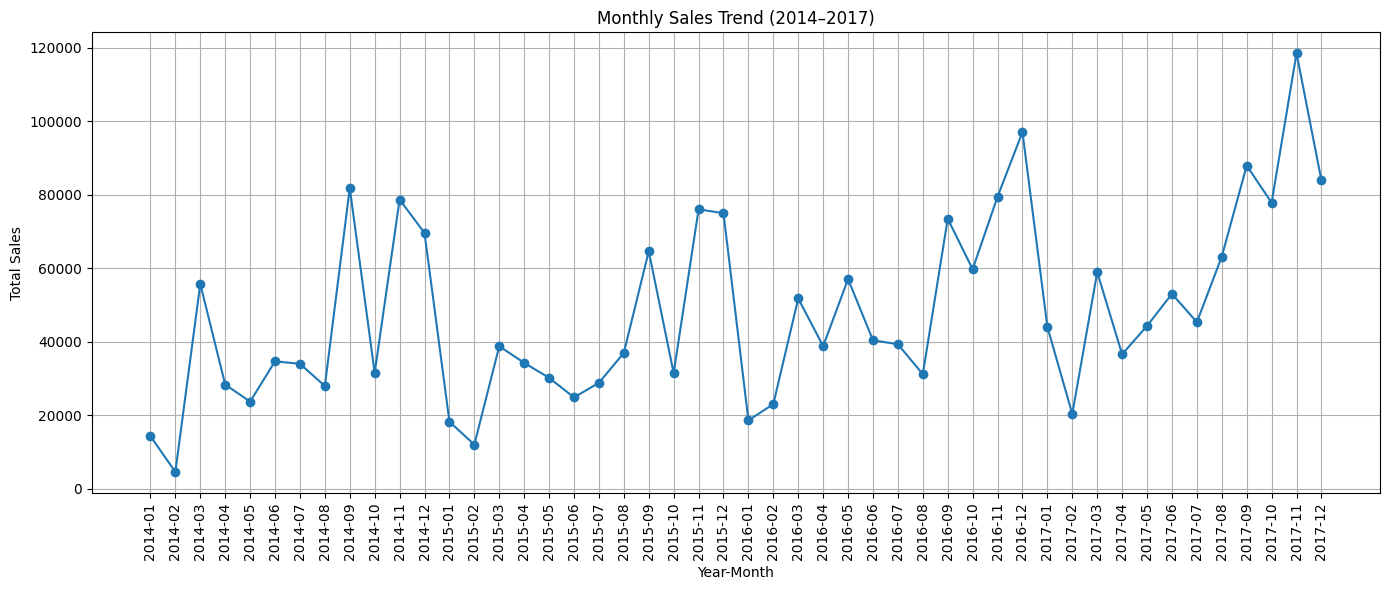

In [ ]:

import matplotlib.pyplot as plt

# Create a date label for each year-month
monthly_sales["Year-Month"] = (
    monthly_sales["Order Year"].astype(int).astype(str)
    + "-"
    + monthly_sales["Order Month"].astype(int).astype(str).str.zfill(2)
)

# Plot monthly sales
plt.figure(figsize=(14, 6))
plt.plot(
    monthly_sales["Year-Month"],
    monthly_sales["Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend (2014–2017)")
plt.xlabel("Year-Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

# Calculate total profit by product category
profit_by_category = (
    df.groupby("Category")["Profit"]
      .sum()
      .sort_values(ascending=False)
)

print("===== PROFIT BY CATEGORY =====")
print(profit_by_category.round(2))


===== PROFIT BY CATEGORY =====
Category
Technology         145454.95
Office Supplies    122490.80
Furniture           18451.27
Name: Profit, dtype: float64


In [ ]:

sales_by_region = (
    df.groupby("Region")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

print("===== SALES BY REGION =====")
print(sales_by_region.round(2))


===== SALES BY REGION =====
Region
West       725457.82
East       678781.24
Central    501239.89
South      391721.90
Name: Sales, dtype: float64


In [ ]:

# Calculate total sales for each customer
top_customers = (
    df.groupby(["Customer ID", "Customer Name"])["Sales"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print("===== TOP 10 CUSTOMERS BY SALES =====")
print(top_customers.round(2))


===== TOP 10 CUSTOMERS BY SALES =====
Customer ID  Customer Name     
SM-20320     Sean Miller           25043.05
TC-20980     Tamara Chand          19052.22
RB-19360     Raymond Buch          15117.34
TA-21385     Tom Ashbrook          14595.62
AB-10105     Adrian Barton         14473.57
KL-16645     Ken Lonsdale          14175.23
SC-20095     Sanjit Chand          14142.33
HL-15040     Hunter Lopez          12873.30
SE-20110     Sanjit Engle          12209.44
CC-12370     Christopher Conant    12129.07
Name: Sales, dtype: float64


In [ ]:

# Calculate total sales for each order
order_totals = df.groupby("Order ID")["Sales"].sum()

# Calculate average order value
average_order_value = order_totals.mean()

print("===== ORDER VALUE ANALYSIS =====")
print("Number of unique orders:", df["Order ID"].nunique())
print("Average order value:", round(average_order_value, 2))
print("Highest order value:", round(order_totals.max(), 2))
print("Lowest order value:", round(order_totals.min(), 2))


===== ORDER VALUE ANALYSIS =====
Number of unique orders: 5009
Average order value: 458.61
Highest order value: 23661.23
Lowest order value: 0.56


In [ ]:

# Analyze sales and profit by product sub-category
subcategory_analysis = (
    df.groupby("Sub-Category")[["Sales", "Profit"]]
    .sum()
    .sort_values(by="Profit", ascending=False)
)

print("===== SALES AND PROFIT BY SUB-CATEGORY =====")
print(subcategory_analysis.round(2))


===== SALES AND PROFIT BY SUB-CATEGORY =====
                  Sales    Profit
Sub-Category                     
Copiers       149528.03  55617.82
Phones        330007.05  44515.73
Accessories   167380.32  41936.64
Paper          78479.21  34053.57
Binders       203412.73  30221.76
Chairs        328449.10  26590.17
Storage       223843.61  21278.83
Appliances    107532.16  18138.01
Furnishings    91705.16  13059.14
Envelopes      16476.40   6964.18
Art            27118.79   6527.79
Labels         12486.31   5546.25
Machines      189238.63   3384.76
Fasteners       3024.28    949.52
Supplies       46673.54  -1189.10
Bookcases     114880.00  -3472.56
Tables        206965.53 -17725.48


In [ ]:

# Check for possible outliers using the IQR method

for column in ["Sales", "Profit"]:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"\n===== {column} OUTLIER CHECK =====")
    print("Lower bound:", round(lower_bound, 2))
    print("Upper bound:", round(upper_bound, 2))
    print("Number of possible outliers:", len(outliers))



===== Sales OUTLIER CHECK =====
Lower bound: -271.71
Upper bound: 498.93
Number of possible outliers: 1167

===== Profit OUTLIER CHECK =====
Lower bound: -39.72
Upper bound: 70.82
Number of possible outliers: 1881


In [ ]:

# Check unique categorical values

categorical_columns = [
    "Category",
    "Sub-Category",
    "Region",
    "Segment",
    "Ship Mode"
]

for column in categorical_columns:
    print(f"\n===== {column} =====")
    print("Number of unique values:", df[column].nunique())
    print(sorted(df[column].dropna().unique()))



===== Category =====
Number of unique values: 3
['Furniture', 'Office Supplies', 'Technology']

===== Sub-Category =====
Number of unique values: 17
['Accessories', 'Appliances', 'Art', 'Binders', 'Bookcases', 'Chairs', 'Copiers', 'Envelopes', 'Fasteners', 'Furnishings', 'Labels', 'Machines', 'Paper', 'Phones', 'Storage', 'Supplies', 'Tables']

===== Region =====
Number of unique values: 4
['Central', 'East', 'South', 'West']

===== Segment =====
Number of unique values: 3
['Consumer', 'Corporate', 'Home Office']

===== Ship Mode =====
Number of unique values: 4
['First Class', 'Same Day', 'Second Class', 'Standard Class']


In [ ]:

# Check for leading or trailing spaces in text columns

text_columns = df.select_dtypes(include="object").columns

print("===== TEXT WHITESPACE CHECK =====")

for column in text_columns:
    spaces = df[column].dropna().apply(
        lambda value: value != value.strip()
    ).sum()

    print(f"{column}: {spaces} values with extra spaces")


===== TEXT WHITESPACE CHECK =====
Order ID: 0 values with extra spaces
Ship Mode: 0 values with extra spaces
Customer ID: 0 values with extra spaces
Customer Name: 0 values with extra spaces
Segment: 0 values with extra spaces
Country: 0 values with extra spaces
City: 0 values with extra spaces
State: 0 values with extra spaces
Region: 0 values with extra spaces
Product ID: 0 values with extra spaces
Category: 0 values with extra spaces
Sub-Category: 0 values with extra spaces
Product Name: 16 values with extra spaces
Order Month Name: 0 values with extra spaces


In [ ]:

# Remove leading and trailing spaces from text columns

text_columns = df.select_dtypes(include="object").columns

for column in text_columns:
    df[column] = df[column].str.strip()

print("===== WHITESPACE CLEANING =====")

for column in text_columns:
    spaces = df[column].dropna().apply(
        lambda value: value != value.strip()
    ).sum()

    print(f"{column}: {spaces} values with extra spaces")


===== WHITESPACE CLEANING =====
Order ID: 0 values with extra spaces
Ship Mode: 0 values with extra spaces
Customer ID: 0 values with extra spaces
Customer Name: 0 values with extra spaces
Segment: 0 values with extra spaces
Country: 0 values with extra spaces
City: 0 values with extra spaces
State: 0 values with extra spaces
Region: 0 values with extra spaces
Product ID: 0 values with extra spaces
Category: 0 values with extra spaces
Sub-Category: 0 values with extra spaces
Product Name: 0 values with extra spaces
Order Month Name: 0 values with extra spaces


In [ ]:

# Final data quality check

print("===== FINAL DATA QUALITY CHECK =====")

print("Dataset shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print("Total duplicate rows:", df.duplicated().sum())

print("\n===== MISSING VALUES BY COLUMN =====")
print(df.isnull().sum())


===== FINAL DATA QUALITY CHECK =====
Dataset shape: (9994, 25)
Total missing values: 0
Total duplicate rows: 0

===== MISSING VALUES BY COLUMN =====
Row ID              0
Order ID            0
Order Date          0
Ship Date           0
Ship Mode           0
Customer ID         0
Customer Name       0
Segment             0
Country             0
City                0
State               0
Postal Code         0
Region              0
Product ID          0
Category            0
Sub-Category        0
Product Name        0
Sales               0
Quantity            0
Discount            0
Profit              0
Shipping Days       0
Order Year          0
Order Month         0
Order Month Name    0
dtype: int64


In [ ]:

# Split the transformed data into related DataFrames

customers_df = df[
    ["Customer ID", "Customer Name", "Segment"]
].drop_duplicates().copy()

products_df = df[
    ["Product ID", "Product Name", "Category", "Sub-Category"]
].drop_duplicates().copy()

orders_df = df[
    [
        "Order ID", "Customer ID", "Order Date", "Ship Date",
        "Ship Mode", "Country", "City", "State",
        "Postal Code", "Region"
    ]
].drop_duplicates(subset=["Order ID"]).copy()

order_details_df = df[
    [
        "Row ID", "Order ID", "Product ID", "Sales",
        "Quantity", "Discount", "Profit"
    ]
].copy()

print("===== TRANSFORMED DATAFRAMES =====")
print("Customers:", customers_df.shape)
print("Products:", products_df.shape)
print("Orders:", orders_df.shape)
print("Order Details:", order_details_df.shape)

print("\n===== KEY CHECKS =====")
print("Unique Customer IDs:", customers_df["Customer ID"].is_unique)
print("Unique Product IDs:", products_df["Product ID"].is_unique)
print("Unique Order IDs:", orders_df["Order ID"].is_unique)
print("Unique Order Detail IDs:", order_details_df["Row ID"].is_unique)


===== TRANSFORMED DATAFRAMES =====
Customers: (793, 3)
Products: (1894, 4)
Orders: (5009, 10)
Order Details: (9994, 7)

===== KEY CHECKS =====
Unique Customer IDs: True
Unique Product IDs: False
Unique Order IDs: True
Unique Order Detail IDs: True


## Phase 4: Analytical Questions and Insights

This phase uses the cleaned dataset to answer business questions about sales, profit, products, regions, and customers. The results help identify strong-performing areas and provide useful information for business decisions.

In [ ]:

# Five analytical questions and their answers

print("===== ANALYTICAL QUESTIONS AND ANSWERS =====")

# 1. Which category generates the highest profit?
print("\n1. Which category generates the highest profit?")
print(df.groupby("Category")["Profit"].sum().idxmax())

# 2. Which region has the highest sales?
print("\n2. Which region has the highest sales?")
print(df.groupby("Region")["Sales"].sum().idxmax())

# 3. Which sub-category generates the highest profit?
print("\n3. Which sub-category generates the highest profit?")
print(df.groupby("Sub-Category")["Profit"].sum().idxmax())

# 4. Which customer has the highest total sales?
print("\n4. Which customer has the highest total sales?")
print(
    df.groupby("Customer Name")["Sales"]
      .sum()
      .idxmax()
)

# 5. What is the average order value?
print("\n5. What is the average order value?")
print(round(df.groupby("Order ID")["Sales"].sum().mean(), 2))


===== ANALYTICAL QUESTIONS AND ANSWERS =====

1. Which category generates the highest profit?
Technology

2. Which region has the highest sales?
West

3. Which sub-category generates the highest profit?
Copiers

4. Which customer has the highest total sales?
Sean Miller

5. What is the average order value?
458.61


### Five Data-Driven Insights

1. **Technology generates the highest profit.** Among the three product categories, Technology contributes the most total profit.

2. **The West region has the highest sales.** This suggests that the West region is an important market for the business.

3. **Copiers generate the highest profit among sub-categories.** Although Copiers are not the highest-selling sub-category, they contribute the most total profit.

4. **Sean Miller is the highest-selling customer.** His total sales are higher than those of any other individual customer in the dataset.

5. **The average order value is $458.61.** On average, each unique order generates $458.61 in sales.

### Additional Findings

The sub-category analysis showed that Copiers generated the highest total profit, while Phones recorded the highest total sales. Tables had the largest total loss among the sub-categories. The monthly sales analysis also showed that November 2017 had the highest monthly sales in the dataset, at approximately $118,447.82. These findings can help the business review product profitability and sales trends.

In [75]:

import os
import sqlite3
import pandas as pd

# Create folder for the database
os.makedirs("data/processed", exist_ok=True)
db_path = "data/processed/superstore.db"

# Prepare the customers table
customers_sql = customers_df.rename(columns={
    "Customer ID": "customer_id",
    "Customer Name": "customer_name",
    "Segment": "segment"
}).copy()

customers_sql = customers_sql.drop_duplicates(
    subset=["customer_id"]
)

# Prepare the products table
products_sql = products_df.rename(columns={
    "Product ID": "product_id",
    "Product Name": "product_name",
    "Category": "category",
    "Sub-Category": "sub_category"
}).copy()

products_sql = products_sql.drop_duplicates(
    subset=["product_id"], keep="first"
)

# Prepare the orders table
orders_sql = orders_df.rename(columns={
    "Order ID": "order_id",
    "Customer ID": "customer_id",
    "Order Date": "order_date",
    "Ship Date": "ship_date",
    "Ship Mode": "ship_mode",
    "Country": "country",
    "City": "city",
    "State": "state",
    "Postal Code": "postal_code",
    "Region": "region"
}).copy()

# Prepare the order details table
details_sql = order_details_df.rename(columns={
    "Row ID": "order_detail_id",
    "Order ID": "order_id",
    "Product ID": "product_id",
    "Sales": "sales",
    "Quantity": "quantity",
    "Discount": "discount",
    "Profit": "profit"
}).copy()

# Format dates consistently
for col in ["order_date", "ship_date"]:
    orders_sql[col] = pd.to_datetime(
        orders_sql[col]
    ).dt.strftime("%Y-%m-%d")

# Open the SQLite database
conn = sqlite3.connect(db_path)
conn.execute("PRAGMA foreign_keys = ON")

# Recreate tables and define primary and foreign keys
conn.executescript("""
DROP TABLE IF EXISTS order_details;
DROP TABLE IF EXISTS orders;
DROP TABLE IF EXISTS products;
DROP TABLE IF EXISTS customers;

CREATE TABLE customers (
    customer_id TEXT PRIMARY KEY,
    customer_name TEXT NOT NULL,
    segment TEXT
);

CREATE TABLE products (
    product_id TEXT PRIMARY KEY,
    product_name TEXT NOT NULL,
    category TEXT,
    sub_category TEXT
);

CREATE TABLE orders (
    order_id TEXT PRIMARY KEY,
    customer_id TEXT NOT NULL,
    order_date TEXT NOT NULL,
    ship_date TEXT,
    ship_mode TEXT,
    country TEXT,
    city TEXT,
    state TEXT,
    postal_code INTEGER,
    region TEXT,
    FOREIGN KEY (customer_id)
        REFERENCES customers(customer_id)
);

CREATE TABLE order_details (
    order_detail_id INTEGER PRIMARY KEY,
    order_id TEXT NOT NULL,
    product_id TEXT NOT NULL,
    sales REAL NOT NULL,
    quantity INTEGER NOT NULL,
    discount REAL,
    profit REAL,
    FOREIGN KEY (order_id)
        REFERENCES orders(order_id),
    FOREIGN KEY (product_id)
        REFERENCES products(product_id)
);
""")

# Load all four DataFrames into SQLite
customers_sql.to_sql(
    "customers", conn, if_exists="append", index=False
)

products_sql.to_sql(
    "products", conn, if_exists="append", index=False
)

orders_sql.to_sql(
    "orders", conn, if_exists="append", index=False
)

details_sql.to_sql(
    "order_details", conn, if_exists="append", index=False
)

conn.commit()

# Verify the number of rows in each table
print("DATABASE CREATED AND LOADED")

for table in [
    "customers", "products", "orders", "order_details"
]:
    count = pd.read_sql_query(
        f"SELECT COUNT(*) AS total_rows FROM {table}",
        conn
    )["total_rows"].iloc[0]

    print(f"{table}: {count:,} rows")

# Check foreign-key relationships
print("\nFOREIGN KEY CHECK")
fk_check = conn.execute(
    "PRAGMA foreign_key_check"
).fetchall()

if not fk_check:
    print("No foreign key violations")
else:
    print(fk_check)

# Confirm database location
print("\nDATABASE FILE:", os.path.abspath(db_path))



DATABASE CREATED AND LOADED
customers: 793 rows
products: 1,862 rows
orders: 5,009 rows
order_details: 9,994 rows

FOREIGN KEY CHECK
No foreign key violations

DATABASE FILE: /Users/ujenamanandhar/Documents/superstore-etl-data-analysis./notebooks/data/processed/superstore.db


In [73]:

import pandas as pd

customers_df = pd.read_csv("data/processed/customers.csv")
products_df = pd.read_csv("data/processed/products.csv")
orders_df = pd.read_csv("data/processed/orders.csv")
order_details_df = pd.read_csv("data/processed/order_details.csv")

print("All four DataFrames loaded successfully.")
print("Customers:", customers_df.shape)
print("Products:", products_df.shape)
print("Orders:", orders_df.shape)
print("Order details:", order_details_df.shape)


All four DataFrames loaded successfully.
Customers: (793, 3)
Products: (1862, 4)
Orders: (5009, 10)
Order details: (9994, 7)


In [76]:

import os
import pandas as pd

# Create a folder for the SQL report outputs
report_folder = "data/processed/sql_reports"
os.makedirs(report_folder, exist_ok=True)

# Eight meaningful SQL reports
sql_reports = {
    "01_sales_by_category": """
        SELECT p.category,
               ROUND(SUM(od.sales), 2) AS total_sales
        FROM order_details od
        JOIN products p ON od.product_id = p.product_id
        GROUP BY p.category
        ORDER BY total_sales DESC;
    """,

    "02_monthly_sales": """
        SELECT strftime('%Y-%m', o.order_date) AS order_month,
               ROUND(SUM(od.sales), 2) AS total_sales
        FROM orders o
        JOIN order_details od ON o.order_id = od.order_id
        GROUP BY order_month
        ORDER BY order_month;
    """,

    "03_top_10_customers": """
        SELECT c.customer_id,
               c.customer_name,
               ROUND(SUM(od.sales), 2) AS total_sales
        FROM customers c
        JOIN orders o ON c.customer_id = o.customer_id
        JOIN order_details od ON o.order_id = od.order_id
        GROUP BY c.customer_id, c.customer_name
        ORDER BY total_sales DESC
        LIMIT 10;
    """,

    "04_top_10_products": """
        SELECT p.product_id,
               p.product_name,
               ROUND(SUM(od.sales), 2) AS total_sales,
               ROUND(SUM(od.profit), 2) AS total_profit
        FROM products p
        JOIN order_details od ON p.product_id = od.product_id
        GROUP BY p.product_id, p.product_name
        ORDER BY total_sales DESC
        LIMIT 10;
    """,

    "05_sales_by_region": """
        SELECT o.region,
               ROUND(SUM(od.sales), 2) AS total_sales,
               ROUND(SUM(od.profit), 2) AS total_profit
        FROM orders o
        JOIN order_details od ON o.order_id = od.order_id
        GROUP BY o.region
        ORDER BY total_sales DESC;
    """,

    "06_average_order_value": """
        SELECT ROUND(AVG(order_total), 2) AS average_order_value
        FROM (
            SELECT order_id, SUM(sales) AS order_total
            FROM order_details
            GROUP BY order_id
        );
    """,

    "07_products_above_average_sales": """
        SELECT p.product_id,
               p.product_name,
               ROUND(SUM(od.sales), 2) AS total_sales
        FROM products p
        JOIN order_details od ON p.product_id = od.product_id
        GROUP BY p.product_id, p.product_name
        HAVING SUM(od.sales) > (
            SELECT AVG(product_sales)
            FROM (
                SELECT SUM(sales) AS product_sales
                FROM order_details
                GROUP BY product_id
            )
        )
        ORDER BY total_sales DESC;
    """,

    "08_profit_classification": """
        SELECT p.category,
               CASE
                   WHEN SUM(od.profit) > 0 THEN 'Profitable'
                   WHEN SUM(od.profit) < 0 THEN 'Loss'
                   ELSE 'Break-even'
               END AS profit_status,
               ROUND(SUM(od.profit), 2) AS total_profit
        FROM products p
        JOIN order_details od ON p.product_id = od.product_id
        GROUP BY p.category
        ORDER BY total_profit DESC;
    """
}

# Run each query, display the results, and save a CSV report
for name, query in sql_reports.items():
    result = pd.read_sql_query(query, conn)
    print("\n" + "=" * 55)
    print(name.upper())
    print("=" * 55)
    display(result)

    result.to_csv(
        os.path.join(report_folder, name + ".csv"),
        index=False
    )

print("\nSUCCESS: All 8 SQL reports were created and saved.")
print("Report folder:", os.path.abspath(report_folder))



01_SALES_BY_CATEGORY


,category,total_sales
0,Technology,836154.03
1,Furniture,741999.80
2,Office Supplies,719047.03



02_MONTHLY_SALES


,order_month,total_sales
0,2014-01,14236.90
1,2014-02,4519.89
2,2014-03,55691.01
3,2014-04,28295.35
4,2014-05,23648.29
5,2014-06,34595.13
6,2014-07,33946.39
7,2014-08,27909.47
8,2014-09,81777.35
9,2014-10,31453.39



03_TOP_10_CUSTOMERS


...


07_PRODUCTS_ABOVE_AVERAGE_SALES


,product_id,product_name,total_sales
0,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,61599.82
1,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.38
2,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,22638.48
3,FUR-CH-10002024,HON 5400 Series Task Chairs for Big and Tall,21870.58
4,OFF-BI-10001359,GBC DocuBind TL300 Electric Binding System,19823.48
...,...,...,...
442,TEC-PH-10001809,Panasonic KX T7736-B Digital phone,1259.58
443,TEC-AC-10001539,Logitech G430 Surround Sound Gaming Headset wi...,1247.84
444,OFF-AP-10000026,Tripp Lite Isotel 6 Outlet Surge Protector wit...,1243.79
445,FUR-CH-10003846,Hon Valutask Swivel Chairs,1242.05



08_PROFIT_CLASSIFICATION


,category,profit_status,total_profit
0,Technology,Profitable,145454.95
1,Office Supplies,Profitable,122490.80
2,Furniture,Profitable,18451.27



SUCCESS: All 8 SQL reports were created and saved.
Report folder: /Users/ujenamanandhar/Documents/superstore-etl-data-analysis./notebooks/data/processed/sql_reports


In [77]:

# Check overall database integrity
print("DATABASE INTEGRITY")
integrity_result = conn.execute(
    "PRAGMA integrity_check"
).fetchall()
print(integrity_result)

# Check foreign-key relationships
print("\nFOREIGN KEY CHECK")
foreign_key_issues = conn.execute(
    "PRAGMA foreign_key_check"
).fetchall()

if foreign_key_issues:
    print("Issues found:", foreign_key_issues)
else:
    print("No foreign key violations")

# Check row counts
print("\nDATABASE TABLE COUNTS")
for table in [
    "customers", "products", "orders", "order_details"
]:
    result = pd.read_sql_query(
        f"SELECT COUNT(*) AS total_rows FROM {table}",
        conn
    )
    print(f"{table}: {result['total_rows'].iloc[0]:,}")

# Check database sales and profit totals
print("\nSALES AND PROFIT TOTALS")
totals = pd.read_sql_query("""
    SELECT
        ROUND(SUM(sales), 2) AS total_sales,
        ROUND(SUM(profit), 2) AS total_profit,
        COUNT(*) AS detail_rows
    FROM order_details
""", conn)

display(totals)


DATABASE INTEGRITY
[('ok',)]

FOREIGN KEY CHECK
No foreign key violations

DATABASE TABLE COUNTS
customers: 793
products: 1,862
orders: 5,009
order_details: 9,994

SALES AND PROFIT TOTALS


,total_sales,total_profit,detail_rows
0,2297200.86,286397.02,9994


In [78]:

import os
import pandas as pd

output_folder = "data/processed"
report_folder = os.path.join(output_folder, "sql_reports")
os.makedirs(report_folder, exist_ok=True)

# Ensure the SQL report includes a WHERE clause.
sql_reports["01_sales_by_category"] = """
    SELECT p.category,
           ROUND(SUM(od.sales), 2) AS total_sales
    FROM order_details od
    JOIN products p ON od.product_id = p.product_id
    WHERE p.category IS NOT NULL
    GROUP BY p.category
    ORDER BY total_sales DESC;
"""

# Refresh all eight CSV reports so they match the SQL file.
for name, query in sql_reports.items():
    result = pd.read_sql_query(query, conn)
    result.to_csv(
        os.path.join(report_folder, name + ".csv"),
        index=False
    )

# Database schema for the SQL deliverable.
schema_sql = """
PRAGMA foreign_keys = ON;

CREATE TABLE customers (
    customer_id TEXT PRIMARY KEY,
    customer_name TEXT NOT NULL,
    segment TEXT
);

CREATE TABLE products (
    product_id TEXT PRIMARY KEY,
    product_name TEXT NOT NULL,
    category TEXT,
    sub_category TEXT
);

CREATE TABLE orders (
    order_id TEXT PRIMARY KEY,
    customer_id TEXT NOT NULL,
    order_date TEXT NOT NULL,
    ship_date TEXT,
    ship_mode TEXT,
    country TEXT,
    city TEXT,
    state TEXT,
    postal_code INTEGER,
    region TEXT,
    FOREIGN KEY (customer_id)
        REFERENCES customers(customer_id)
);

CREATE TABLE order_details (
    order_detail_id INTEGER PRIMARY KEY,
    order_id TEXT NOT NULL,
    product_id TEXT NOT NULL,
    sales REAL NOT NULL,
    quantity INTEGER NOT NULL,
    discount REAL,
    profit REAL,
    FOREIGN KEY (order_id)
        REFERENCES orders(order_id),
    FOREIGN KEY (product_id)
        REFERENCES products(product_id)
);
"""

# Create a .sql file containing the schema and all eight queries.
sql_file_content = [
    "-- Superstore ETL and Data Analysis Project",
    "-- Schema and eight analytical SQL reports",
    "-- Run the CREATE TABLE statements on an empty database.",
    "",
    schema_sql,
    "",
    "-- ANALYTICAL REPORT QUERIES",
]

for name, query in sql_reports.items():
    sql_file_content.append("\n-- " + name.replace("_", " ").title())
    sql_file_content.append(query.strip())

sql_file_path = os.path.join(
    output_folder, "superstore_reports.sql"
)

with open(sql_file_path, "w", encoding="utf-8") as file:
    file.write("\n".join(sql_file_content) + "\n")

# Create the ERD document using Mermaid notation.
erd_content = """# Superstore Database ERD

```mermaid
erDiagram
    CUSTOMERS ||--o{ ORDERS : places
    ORDERS ||--|{ ORDER_DETAILS : contains
    PRODUCTS ||--o{ ORDER_DETAILS : appears_in

    CUSTOMERS {
        string customer_id PK
        string customer_name
        string segment
    }

    ORDERS {
        string order_id PK
        string customer_id FK
        string order_date
        string ship_date
        string ship_mode
        string city
        string state
        string region
    }

    PRODUCTS {
        string product_id PK
        string product_name
        string category
        string sub_category
    }

    ORDER_DETAILS {
        integer order_detail_id PK
        string order_id FK
        string product_id FK
        real sales
        integer quantity
        real discount
        real profit
    }
```

The customers table connects to orders through customer_id.
The orders table connects to order_details through order_id.
The products table connects to order_details through product_id.
"""

erd_path = os.path.join(output_folder, "ERD.md")

with open(erd_path, "w", encoding="utf-8") as file:
    file.write(erd_content)

# Collect verified totals from the database.
totals = pd.read_sql_query("""
    SELECT ROUND(SUM(sales), 2) AS total_sales,
           ROUND(SUM(profit), 2) AS total_profit,
           COUNT(*) AS detail_rows
    FROM order_details
""", conn)

total_sales = totals.loc[0, "total_sales"]
total_profit = totals.loc[0, "total_profit"]
detail_rows = int(totals.loc[0, "detail_rows"])

category_profit = pd.read_sql_query("""
    SELECT p.category, ROUND(SUM(od.profit), 2) AS total_profit
    FROM products p
    JOIN order_details od ON p.product_id = od.product_id
    GROUP BY p.category
    ORDER BY total_profit DESC
""", conn)

region_sales = pd.read_sql_query("""
    SELECT o.region, ROUND(SUM(od.sales), 2) AS total_sales
    FROM orders o
    JOIN order_details od ON o.order_id = od.order_id
    GROUP BY o.region
    ORDER BY total_sales DESC
""", conn)

aov_result = pd.read_sql_query("""
    SELECT ROUND(AVG(order_total), 2) AS average_order_value
    FROM (
        SELECT order_id, SUM(sales) AS order_total
        FROM order_details
        GROUP BY order_id
    )
""", conn)

average_order_value = aov_result.loc[0, "average_order_value"]

# Create the project report.
project_report = f"""# End-to-End ETL and Data Analysis Pipeline
## Superstore Dataset

### 1. Introduction
This project builds an end-to-end ETL and data analysis pipeline using the Superstore dataset. Python and Pandas are used to explore, clean, transform, and analyze the data. SQLite is used to store the processed data in related tables, and SQL queries are used to produce business reports.

### 2. Project Objectives
- Explore and understand the dataset.
- Identify and address data-quality issues.
- Create useful calculated columns and analysis tables.
- Build a relational database with primary and foreign keys.
- Load data into the database and validate it.
- Answer business questions using Python and SQL.
- Present findings through analysis, charts, and reports.

### 3. Dataset and Extraction
The project uses the Superstore sales dataset obtained for this assignment from Kaggle. It contains order, customer, product, sales, discount, quantity, and profit information. The original dataset contains 9,994 rows and 21 columns. The raw source data is retained separately from the processed files.

### 4. Exploratory Data Analysis
The notebook examines the dataset's dimensions, column names, data types, descriptive statistics, unique values, and data quality. It also explores sales and profit by category, region, sub-category, customer, and month.

### 5. Data Cleaning and Transformation
The notebook converts order and shipping dates to datetime values, checks missing values and duplicate rows, cleans whitespace in product names, and creates the Shipping Days, Order Year, Order Month, and Order Month Name columns. It also creates separate customer, product, order, and order-detail DataFrames for database loading.

The product table uses one record per Product ID to meet the primary-key requirement. Where a Product ID has more than one descriptive record, the first record is retained in the product table. The original order-detail records are retained. This is a database-normalization choice and a limitation to document if product descriptions conflict.

### 6. Database Design and ETL
The SQLite database is saved at `data/processed/superstore.db`. It contains four related tables: customers, products, orders, and order_details. Primary keys identify records, and foreign keys connect orders to customers and order details to orders and products. Python loads the prepared DataFrames into these tables.

### 7. Data Validation
The database validation cell checks database integrity, foreign-key relationships, table row counts, and sales and profit totals. The validation results should be reviewed before final submission.

Verified order-detail rows: {detail_rows:,}

Database total sales: ${total_sales:,.2f}

Database total profit: ${total_profit:,.2f}

### 8. Analytical Findings
- Technology generated the highest profit among the product categories in the notebook's category analysis.
- The West region recorded the highest sales in the notebook's regional analysis.
- Copiers generated the highest total profit among sub-categories.
- Phones recorded the highest total sales among sub-categories.
- Tables had the largest total loss among sub-categories.
- November 2017 recorded the highest monthly sales in the notebook's monthly analysis, at approximately $118,447.82.
- Sean Miller was the highest-sales customer in the notebook's customer analysis, with total sales of approximately $25,043.05.
- The average order value calculated from the order-detail records was ${average_order_value:,.2f}.

### 9. SQL Reports
Eight SQL reports are included:
1. Sales by product category.
2. Monthly sales trends.
3. Top 10 customers by sales.
4. Top 10 products by sales.
5. Sales and profit by region.
6. Average order value.
7. Products above average total sales.
8. Profit classification by category using CASE.

The queries demonstrate JOIN, WHERE, GROUP BY, HAVING, ORDER BY, aggregate functions, a subquery, and CASE. The query results are exported as CSV files.

### 10. Project Deliverables
- Jupyter notebook containing extraction, exploration, cleaning, transformation, analysis, and database loading.
- Original raw dataset.
- Processed customer, product, order, and order-detail CSV files.
- SQLite database.
- SQL schema and analytical queries.
- Entity Relationship Diagram (ERD).
- Eight SQL report CSV files.
- This project report.

### 11. Challenges and Limitations
The project required checks for duplicate product identifiers because a relational product table requires each Product ID to be unique. One descriptive record per Product ID was retained for the database, while the original order-detail rows were preserved. The database checks and total reconciliation help verify that the loaded order details remain complete.

### 12. Conclusion
This project demonstrates a complete workflow from raw sales data to data cleaning, transformation, relational database loading, SQL reporting, and business insights. The results help identify profitable categories, strong sales regions, customer contributions, and sub-category performance. Database validation and the saved project files make the work easier to review and reproduce.
"""

report_path = os.path.join(output_folder, "project_report.md")

with open(report_path, "w", encoding="utf-8") as file:
    file.write(project_report)

print("DELIVERABLE FILES CREATED")
print(os.path.abspath(sql_file_path))
print(os.path.abspath(erd_path))
print(os.path.abspath(report_path))
print("Eight SQL report CSVs refreshed.")


DELIVERABLE FILES CREATED
/Users/ujenamanandhar/Documents/superstore-etl-data-analysis./notebooks/data/processed/superstore_reports.sql
/Users/ujenamanandhar/Documents/superstore-etl-data-analysis./notebooks/data/processed/ERD.md
/Users/ujenamanandhar/Documents/superstore-etl-data-analysis./notebooks/data/processed/project_report.md
Eight SQL report CSVs refreshed.


In [ ]:

import os

required_files = [
    "data/processed/customers.csv",
    "data/processed/products.csv",
    "data/processed/orders.csv",
    "data/processed/order_details.csv",
    "data/processed/superstore.db",
    "data/processed/superstore_reports.sql",
    "data/processed/ERD.md",
    "data/processed/project_report.md"
]

print("===== REQUIRED FILES =====")

all_files_exist = True

for path in required_files:
    exists = os.path.isfile(path)
    print(("OK       " if exists else "MISSING  ") + path)
    if not exists:
        all_files_exist = False

print("\n===== SQL REPORT CSV FILES =====")

report_folder = "data/processed/sql_reports"
report_files = []

if os.path.isdir(report_folder):
    report_files = sorted([
        name for name in os.listdir(report_folder)
        if name.endswith(".csv")
    ])

for name in report_files:
    print(name)

print("\nSQL report CSV count:", len(report_files))
print("All required files exist:", all_files_exist)
print("All eight SQL reports exist:", len(report_files) == 8)

print("\n===== RAW DATA FOLDER =====")
if os.path.isdir("data/raw"):
    print(os.listdir("data/raw"))
else:
    print("data/raw folder not found. Check where your original dataset is saved.")
